# **Notebook Outline with Code Snippets**

Author: Camilla Carpinelli

# **1. Import Libraries**

If you don't have all the libraries, download them with !pip download "name_library"

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing, Holt
from statsmodels.tsa.api import SimpleExpSmoothing
from statsmodels.tsa.arima.model import ARIMA
from pmdarima import auto_arima
from statsmodels.tsa.forecasting.theta import ThetaModel
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, train_test_split

# **2. Load and Inspect Data**

In [2]:
# Load data
# Load dataset
data = pd.read_csv('AirPassengers.csv', parse_dates=['Month'], index_col='Month')
data.columns = ['Passengers']  # Rename column for clarity
data

,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
...,...
1960-08-01,606
1960-09-01,508
1960-10-01,461


In [3]:
# Basic checks
data.info()
data.describe()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB


,Passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000


# **3. Plotting the Time Series**

Split the dataset into training and testing sets, and plot them in different colors.

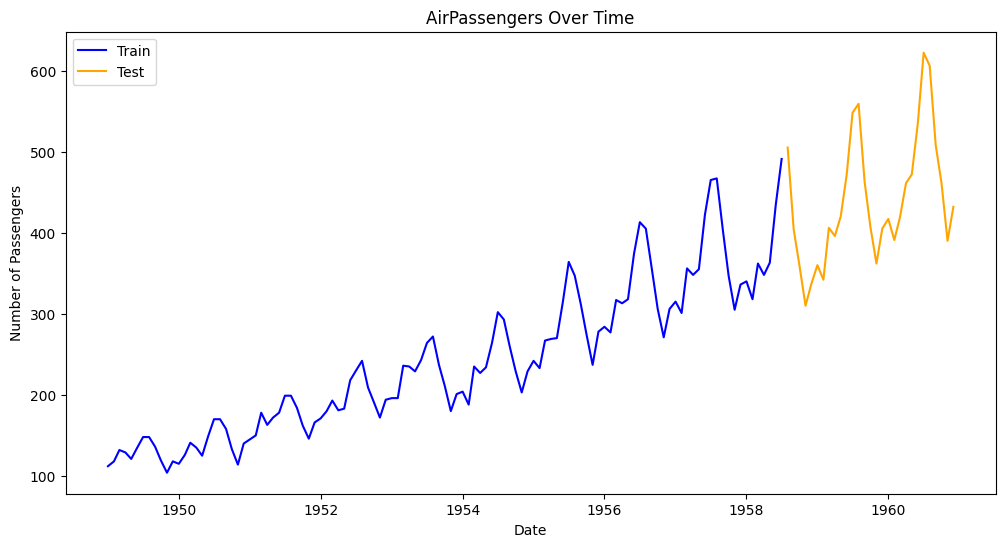

In [4]:
# Train-test split
train_size = int(0.8 * len(data))
train, test = data[:train_size], data[train_size:]

# Plot
plt.figure(figsize=(12, 6))
plt.plot(train, label='Train', color='blue')
plt.plot(test, label='Test', color='orange')
plt.xlabel('Date')
plt.ylabel('Number of Passengers')
plt.title('AirPassengers Over Time')
plt.legend()
plt.show()

# **4. Decomposition: Additive and Multiplicative Models**

Apply seasonal decomposition to isolate trends, seasonality, and residual noise.

Recognizing whether a time series is multiplicative or additive typically depends on how the seasonal fluctuations vary with the trend. Here’s a breakdown of how you can identify a multiplicative model:

**Pattern in Seasonality Amplitude**

*Additive Model:* The seasonal fluctuations remain constant over time. For example, if you observe similar-sized seasonal peaks or troughs throughout the time series, it’s likely an additive model.

*Multiplicative Model:* The amplitude of the seasonal patterns increases or decreases with the trend. This means that as the trend rises, the seasonal fluctuations become more pronounced, and as the trend falls, they shrink.

When you decompose the series (using seasonal_decompose), a multiplicative decomposition will often yield more stable seasonal and residual components if the data is truly multiplicative. The AirPassengers dataset decomposition likely shows this, as the seasonal component in a multiplicative model would vary proportionally with the trend.

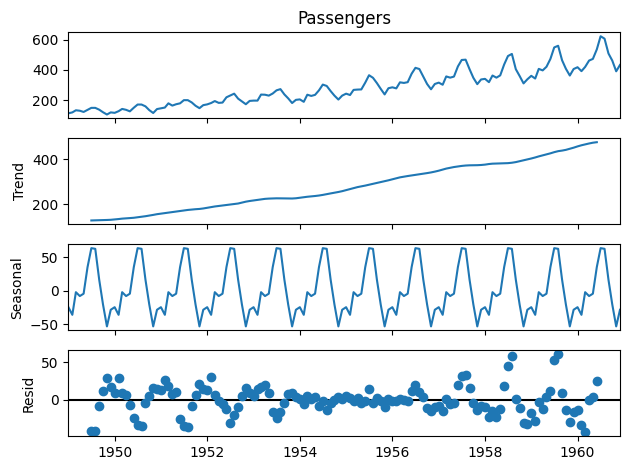

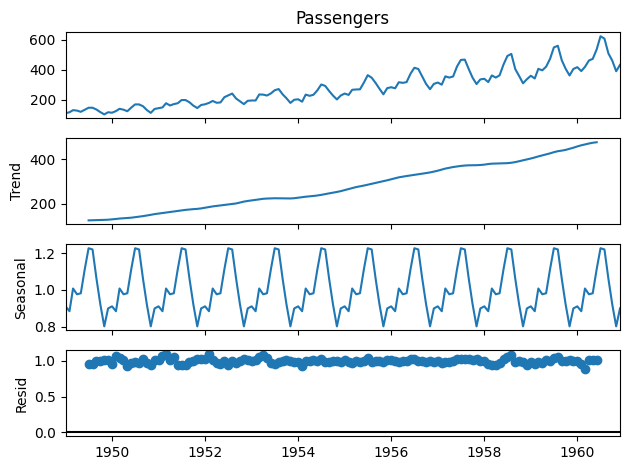

In [5]:
from statsmodels.tsa.seasonal import seasonal_decompose
import numpy as np

# Original data plot
decomposition_add = seasonal_decompose(data['Passengers'], model='additive')
decomposition_mult = seasonal_decompose(data['Passengers'], model='multiplicative')

# Plot both decompositions
decomposition_add.plot()
decomposition_mult.plot()
plt.show()

**Understanding Time Series Components**

*Frequency:* Monthly data with a clear seasonal pattern.

*Trend:* Increasing trend over the years.

*Seasonality:* Repeats annually.

*Cycles:* Patterns that emerge over multi-year periods.

*Noise (Residuals):* Random fluctuations.

# **5. Autocorrelation and Partial Autocorrelation**

Plot autocorrelation (ACF) and partial autocorrelation (PACF) to assess the dependency structure.

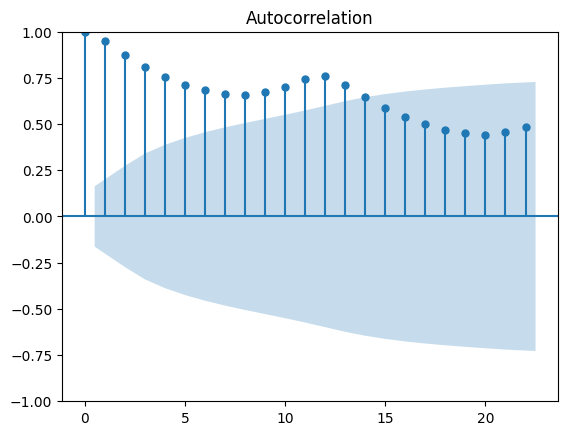

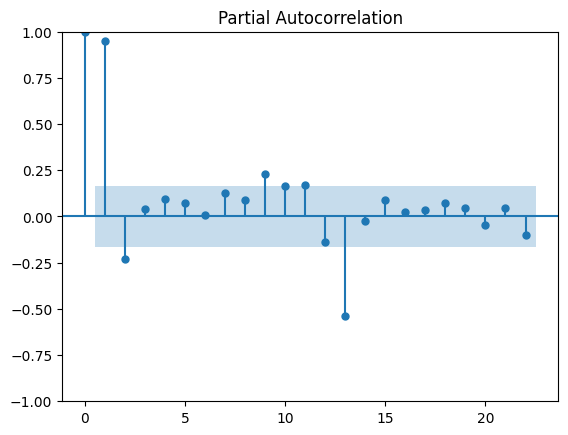

In [6]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(data['Passengers'])
plot_pacf(data['Passengers'])
plt.show()

**Interpreting the ACF and PACF Results**

*Autocorrelation Function (ACF):*

The ACF plot shows the correlation between the time series and its lagged values over various lag periods.
If we see a slow decay in autocorrelation (e.g., high values that gradually decrease as the lags increase), this suggests a non-stationary series with a trend. This pattern is common in time series that are not yet differenced.
A sharp cutoff after a few lags typically indicates an AR component, while a sinusoidal or oscillating pattern could suggest seasonality.

*Partial Autocorrelation Function (PACF):*

The PACF plot, on the other hand, shows the correlation between the series and its lagged values, excluding the influence of intermediate lags.
If there’s a significant spike at lag 1 in the PACF and then a drop to near zero afterward, it might suggest an AR(1) process (Auto-Regressive model of order 1).

For higher-order AR processes, we may see a significant spike at multiple initial lags before PACF values diminish.

**Identifying Models with ACF and PACF**

*ARIMA Model:*

If you observe a slow decay in the ACF and a sharp cutoff in the PACF (usually after lag 1 or 2), this is a common pattern for an AR model.

For an MA model, you might see the opposite: a sharp cutoff in the ACF and a gradual decay in the PACF.

For ARIMA models with both AR and MA terms, you’ll usually observe a combination of these patterns.

**Example Observations**

*In a typical dataset like AirPassengers:*

ACF might show periodic spikes at seasonal intervals (e.g., lags 12, 24, etc.) if seasonality exists, along with a high correlation at lag 1, indicating short-term dependence.

PACF may show significant correlations at early lags, hinting at potential AR components, or at multiples of the seasonal period, indicating that the seasonality may need to be modeled explicitly.

These insights guide model selection, helping to define appropriate AR and MA orders for ARIMA or seasonal ARIMA models.

# **6. Stationarity Tests**

Use the Augmented Dickey-Fuller (ADF) test to check for stationarity.

In [7]:
result = adfuller(data['Passengers'])
print(f"ADF Statistic: {result[0]}")
print(f"p-value: {result[1]}")

ADF Statistic: 0.8153688792060482
p-value: 0.991880243437641


p-value > 0.05 so data is not stationary.

When a time series is not stationary, it has trends, seasonality, or other patterns that change over time. Many forecasting models, such as ARIMA, assume stationarity, so we often need to transform the data to make it stationary before applying these models. Here’s a step-by-step approach for handling non-stationary data:

**Differencing**

Differencing helps remove trends and stabilize the mean of a time series by subtracting each observation from the previous one.
First-order differencing is often enough to make a series stationary, but sometimes seasonal differencing (e.g., differencing with a lag equal to the seasonal period) is also necessary.

In [8]:
# First-order differencing
data_diff1 = data['Passengers'].diff().dropna()

**Log Transformation**

A logarithmic transformation can help stabilize the variance, especially if the seasonal amplitude increases with the trend (common in multiplicative time series).

This transformation is often applied before differencing if the seasonal variation appears to be multiplicative.

In [9]:
# Log transformation
data_log = np.log(data['Passengers'])

# Seasonal differencing (if monthly data, usually lag=12)
data_diff_seasonal = data['Passengers'].diff(12).dropna()

**Combining Log Transformation and Differencing**

For some datasets, applying a log transformation followed by differencing (either first-order or seasonal) can be effective in achieving stationarity.

In [10]:
data_log_diff1 = data_log.diff().dropna()  # Log followed by first differencing
data_log_diff_seasonal = data_log.diff(12).dropna()  # Log followed by seasonal differencing

**Check Stationarity Again**

Run the ADF test after each transformation to check if the series has become stationary. If the p-value from the test is below the significance level (typically 0.05), the transformed series is stationary

In [11]:
# ADF Test on transformed data
result = adfuller(data_log_diff1.dropna())
print(f"ADF Statistic: {result[0]}")
print(f"p-value: {result[1]}")

ADF Statistic: -2.717130598388133
p-value: 0.07112054815085875


p > 0.05, data is still non-stationary

**Second-Order Differencing**

Sometimes a second round of differencing can help. For instance, you could apply a second-order differencing if the series has persistent trends or non-stationarity even after a first-order difference.

This involves differencing the data twice, which can be helpful for stronger trends.

In [12]:
data_diff2 = data['Passengers'].diff().diff().dropna()

**Seasonal and First-Order Differencing Combined**

If there’s a seasonal pattern, you can combine seasonal differencing with a first-order difference. For example, if the data is monthly and shows a yearly cycle, applying a lag-12 difference followed by a first-order difference can sometimes stabilize it.

In [13]:
data_diff_seasonal_first = data['Passengers'].diff(12).diff().dropna()

**Re-test Stationarity**

After each transformation, you should re-run the ADF test to check if stationarity has been achieved.

In [14]:
result = adfuller(data_diff_seasonal_first.dropna())
print(f"ADF Statistic: {result[0]}")
print(f"p-value: {result[1]}")

ADF Statistic: -15.595618083746334
p-value: 1.8565116001234705e-28


Now p is definetly less than 0.05, so the data is stationary

**Re-test ACF and PACF**

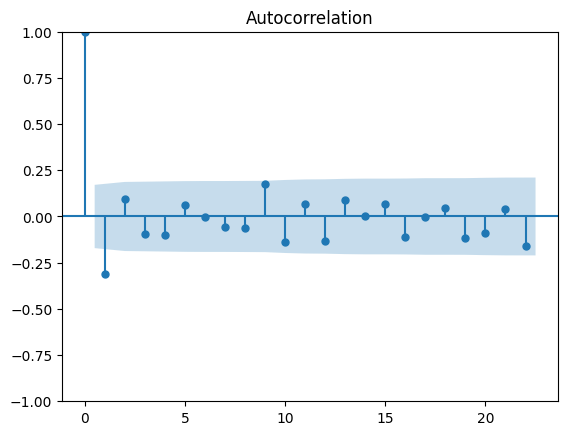

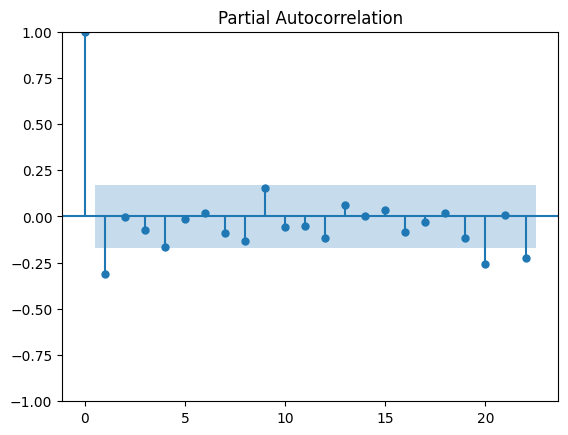

In [15]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(data_diff_seasonal_first)
plot_pacf(data_diff_seasonal_first)
plt.show()

# **7. Structural Breaks**

Sometimes, non-stationarity is due to structural breaks or changes in the pattern over time. You can test for these breaks and handle them by modeling segments of the data separately if they are known (using methods like the Chow test or CUSUM test for change points).

For Structural Breaks Analysis, it is recommended to use R, since some libraries that python uses are deprecated.

You can run the following code on RStudio:

install.packages("tidyverse")

install.packages("ggplot2")

install.packages("lubridate")

install.packages("forecast")

install.packages("xts")

install.packages("strucchange")

install.packages("CPAT")

library(tidyverse)

library(ggplot2)

library(lubridate)

library(forecast)

library(tseries)

library(xts)

library(strucchange)

library(CPAT)


**Read the data**

data <- read_csv("YOURPATH/AirPassengers.csv")

head(data)


**#1. Define Passengers as a Time Series Object**

Passengers <- ts(data$`#Passengers`, start = 1949, end = 1960, frequency = 12)

*#From previous analysis, we know that the data is not stationary. Anyways, in Structural Break Analysis*

*#You could test for breaks using several breakpoint tests just fine.*

*#It is the other direction that you should be extra careful.*

*#Tests for stationarity or unit root are biased in the presence of a structural break.*


**#2. We go on with the search for structural changes.**

bp.Passengers <- breakpoints(Passengers~1, data = data, h = 0.1, breaks = 8)

plot(bp.Passengers)

*#To interpret this graph, we want to choose the number of breakpoints*

*#where the BIC and RSS cross. We see that this cross happens around*

*#the two-in-a-half mark; however, we only want to choose full breaks, not partial;*

*#thus, we’ll continue this analysis assuming two breaks.*


**#3. The plot of the observed and fitted time series, along with confidence**
**#intervals for the breakpoints, is given by:**

plot(Passengers) 
lines(fitted(bp.Passengers, breaks = 2), lwd = 3, col = 'blue')
lines(confint(bp.Passengers, breaks = 2), lwd = 3)


**#4. Now we want to figure out where the breaks are located:**

confint(bp.Passengers, breaks =2)

*#Creating a confidence interval for breakpoints of optimal 3-segment partition,*

*#we find that the first break is between February 1952 and June 1952,.*

*#while the second one is between November 1955 and March 1956*

# **8. Preprocessing**

For preprocessing, we’ll remove the trend and seasonal effects, as well as smooth out any outliers in the AirPassengers data. Here’s a breakdown of each step:

**1. Removing Trends and Seasonality:** We’ll use differencing and seasonal decomposition to isolate and remove these components. The code is the same as topic 4 (**Decomposition**) and 6 (**Stationarity Tests** - Differencing)

In [16]:
# Step 1: Removing Trend using Differencing
data_diff = data.diff().dropna()

# Step 2: Removing Seasonality using Seasonal Decomposition
decomposition = seasonal_decompose(data, model='multiplicative', period=12)
data_deseasonalized = data.Passengers / decomposition.seasonal
data_deseasonalized = data_deseasonalized.dropna()

**2. Smoothing Out Outliers:** Apply a moving average filter to reduce the impact of outliers.

In [17]:
# Applying a rolling window to smooth the data
window_size = 3  # you can adjust this depending on the level of smoothing needed
data_smoothed = data_deseasonalized.rolling(window=window_size, center=True).mean()
data_smoothed = data_smoothed.dropna()

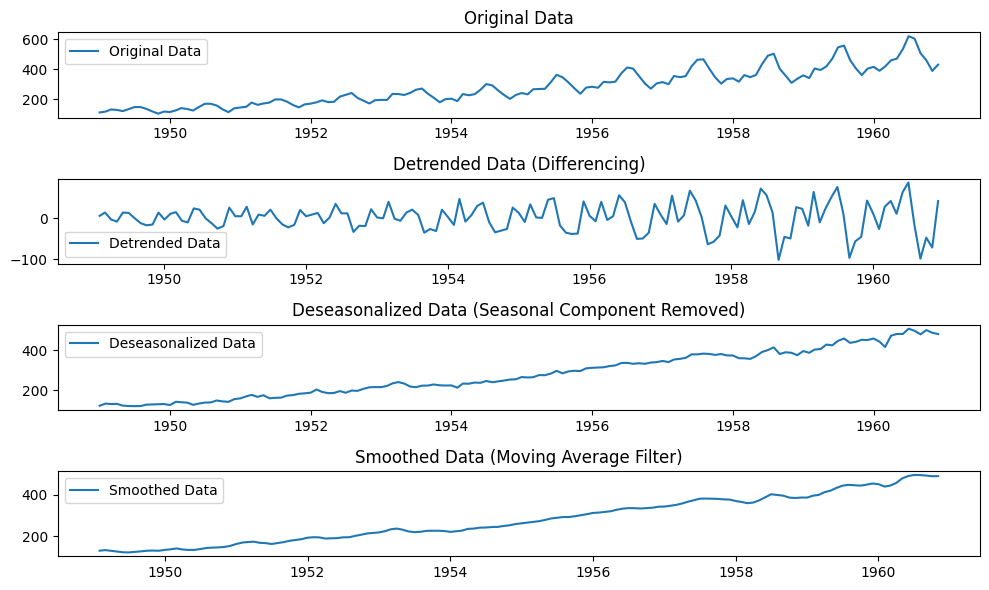

In [18]:
# Plotting the Results
plt.figure(figsize=(10, 6))

plt.subplot(4, 1, 1)
plt.plot(data, label="Original Data")
plt.title("Original Data")
plt.legend()

plt.subplot(4, 1, 2)
plt.plot(data_diff, label="Detrended Data")
plt.title("Detrended Data (Differencing)")
plt.legend()

plt.subplot(4, 1, 3)
plt.plot(data_deseasonalized, label="Deseasonalized Data")
plt.title("Deseasonalized Data (Seasonal Component Removed)")
plt.legend()

plt.subplot(4, 1, 4)
plt.plot(data_smoothed, label="Smoothed Data")
plt.title("Smoothed Data (Moving Average Filter)")
plt.legend()

plt.tight_layout()
plt.show()

**Explanation of Each Step**

**Differencing:** By taking the first difference, we remove the trend component, which can help make the data more stationary.

**Deseasonalizing:** Seasonal decomposition splits the time series into trend, seasonal, and residual components. We divide the original data by the seasonal component to remove seasonality.

**Smoothing:** Applying a moving average filter reduces noise by smoothing out abrupt fluctuations or outliers, making the series easier to work with for modeling.

This preprocessing makes the data more stationary and removes patterns, which can be particularly useful for models that perform better with stationary, detrended, and deseasonalized data. Adjusting the *window_size* in the moving average filter can help you control the level of smoothing, depending on the amount of noise or outliers present.

# **9. Forecasting**

We use *train, test* from step **3**.

In [19]:
# Forecast horizon
forecast_horizon = len(test)

In [20]:
# Helper function to calculate and plot forecast
def plot_forecast(forecast, model_name):
    plt.figure(figsize=(10, 6))
    plt.plot(data, label="Original Data")
    plt.plot(train, label="Train Data", color="blue")
    plt.plot(test, label="Test Data", color="green")
    plt.plot(forecast, label=f"{model_name} Forecast", color="red")
    plt.fill_between(forecast.index, forecast - 1.96 * forecast.std(), forecast + 1.96 * forecast.std(), color='red', alpha=0.2)
    plt.title(f"{model_name} Forecast with Confidence Intervals")
    plt.legend()
    plt.show()


**1. Naïve Forecasting Model**

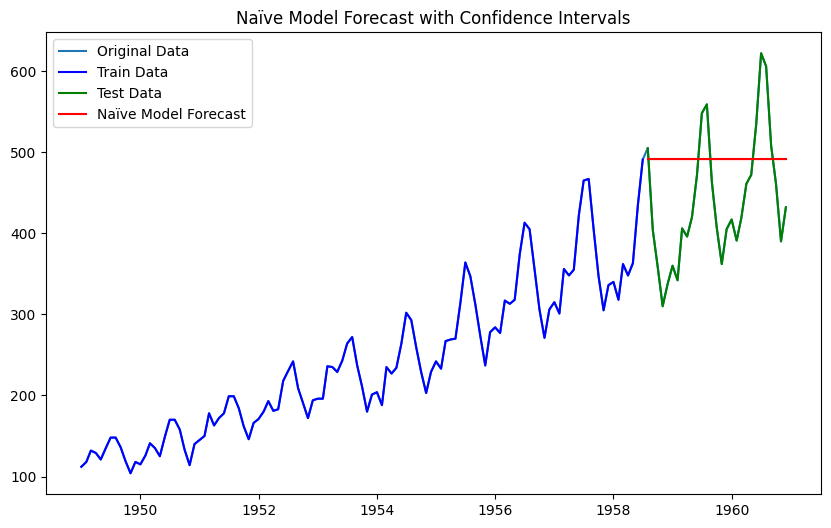

In [21]:
# 1. Naïve Forecasting Model
# Extract the last numeric value from the training data
last_value = train['Passengers'].iloc[-1]

# Create the forecast by repeating this value for each point in the forecast horizon
naive_forecast = pd.Series([last_value] * len(test), index=test.index)

# Plot the forecast
plot_forecast(naive_forecast, "Naïve Model")

The Naïve model predicts a straight line because it assumes that the last observed value will remain constant into the future, which often results in a flat forecast. If you want to incorporate more meaningful patterns, you can try additional methods that consider seasonality or trends. Here are some models you can explore:

**Seasonal Naïve Model**: Assumes that future values will follow the same seasonal pattern as past observations.

**Moving Average**: Smooths the data by averaging recent points, which can reflect general trends without just repeating the last value.

**STL Decomposition + Forecasting**: Separates the trend, seasonality, and residual components, allowing you to forecast each separately and then combine them.

**2. Seasonal Naïve Model**

This approach repeats the same seasonal pattern as observed in previous years.

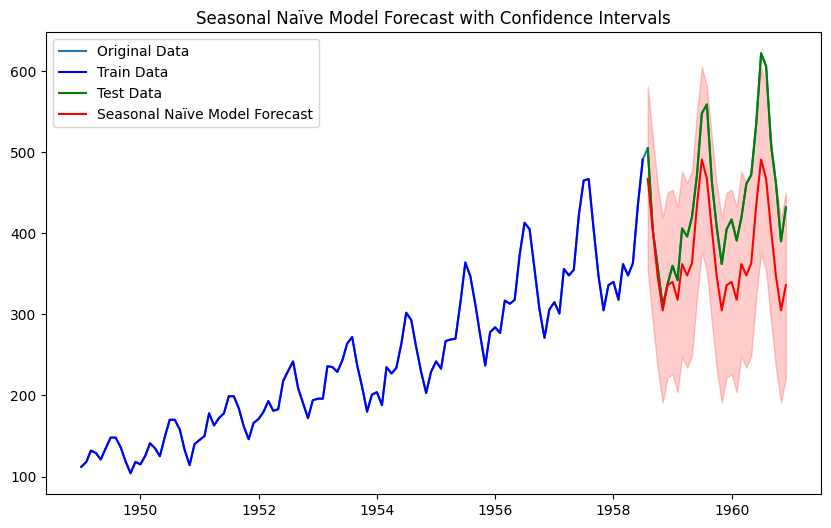

In [22]:
# Seasonal Naïve Model
seasonal_period = 12  # Assuming monthly data with annual seasonality

# Create the seasonal forecast by repeating the last full seasonal cycle
seasonal_naive_values = (train['Passengers'].iloc[-seasonal_period:].values.tolist() * (len(test) // seasonal_period + 1))[:len(test)]
seasonal_naive_forecast = pd.Series(seasonal_naive_values, index=test.index)

# Plot the forecast
plot_forecast(seasonal_naive_forecast, "Seasonal Naïve Model")

**3. Moving Average Model**

This model forecasts based on the average of the last few months.

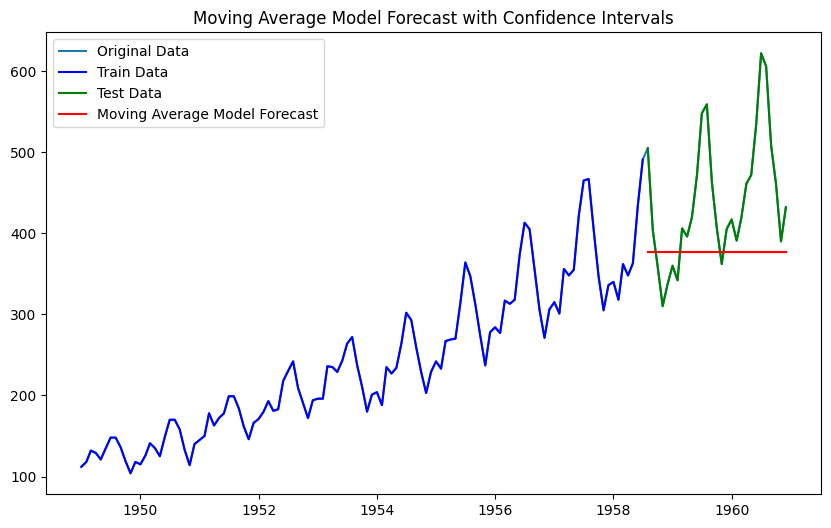

In [23]:
# Moving Average Forecast
window_size = 12  # Averaging over the last 12 months for seasonal trend
moving_avg_forecast = test.copy()
moving_avg_forecast['Passengers'] = train['Passengers'].rolling(window=window_size).mean().iloc[-1]

# Plot the forecast
plot_forecast(moving_avg_forecast['Passengers'], "Moving Average Model")

If you're getting a flat line in your moving average model, it might be due to the structure of the moving average method we're using. A basic moving average simply smooths past values and can’t capture trends or seasonality on its own, especially if the series has strong seasonality, as is the case with the AirPassengers dataset.

A better approach for time series with seasonality would be to implement a **Rolling Moving Average Forecast**, where we update the moving average as we move through the forecasted points

**4. Rolling Moving Average Forecast**

In a rolling forecast, we update the forecast each period by adding new observations to the moving average. 

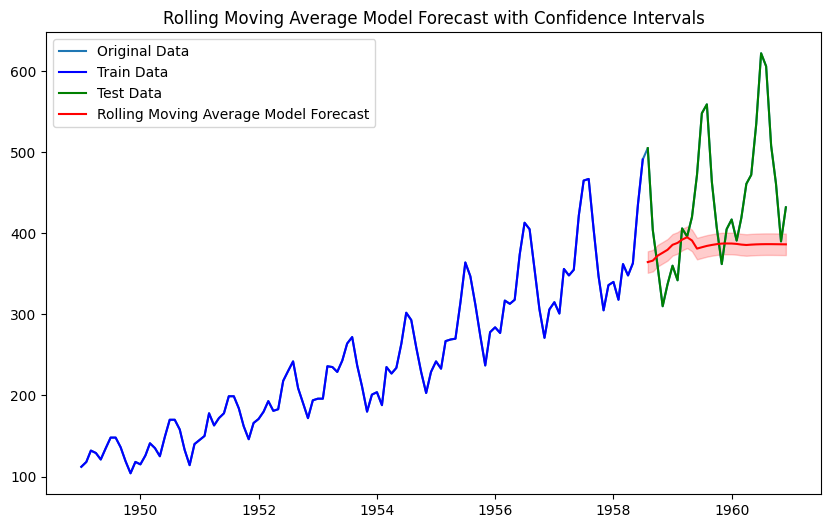

In [24]:
# Rolling Moving Average Model
moving_avg_window = 10  # Try different windows if needed

# Initialize an empty list to store predictions
rolling_moving_avg_forecast = []

# Loop through each test period to update the rolling forecast
for i in range(len(test)):
    # Calculate moving average using the latest values from the training set + any predicted values
    if i == 0:
        # Initial prediction based on the last moving average from the training set
        avg = train['Passengers'].rolling(window=moving_avg_window).mean().iloc[-1]
    else:
        # Rolling window based on previous predictions in the test period
        avg = pd.concat([train['Passengers'], pd.Series(rolling_moving_avg_forecast)], ignore_index=True).rolling(window=moving_avg_window).mean().iloc[-1]
    
    rolling_moving_avg_forecast.append(avg)

# Convert to Series and plot
rolling_moving_avg_forecast_series = pd.Series(rolling_moving_avg_forecast, index=test.index)
plot_forecast(rolling_moving_avg_forecast_series, "Rolling Moving Average Model")

**5. STL Decomposition + Forecasting**

Using STL decomposition allows you to separate seasonal and trend components, which can then be forecasted separately.

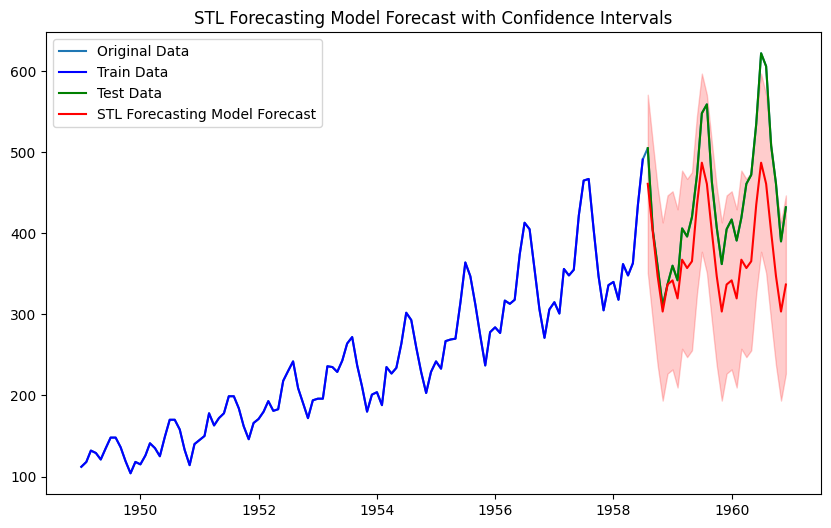

In [25]:
# Perform STL decomposition
stl = STL(train['Passengers'], seasonal=13)  # Assuming monthly seasonality
result = stl.fit()

# Forecast based on the trend and seasonality components
trend_forecast = result.trend.iloc[-1]  # Last observed trend level
seasonal_forecast = result.seasonal[-seasonal_period:]  # Repeat last season
seasonal_forecast = pd.Series(np.tile(seasonal_forecast.values, len(test) // seasonal_period + 1)[:len(test)], index=test.index)

# Combine trend and seasonality for final forecast
stl_forecast = trend_forecast + seasonal_forecast

# Plot the forecast
plot_forecast(stl_forecast, "STL Forecasting Model")

**6. Exponential Smoothing + Holt-Winters (to Capture Trend and Seasonality)**

Exponential smoothing can handle trend and seasonality if you use the Holt-Winters model.

Holt-Winters adds support for seasonality and trend in the exponential smoothing, making it a better option for time series with strong patterns.

c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


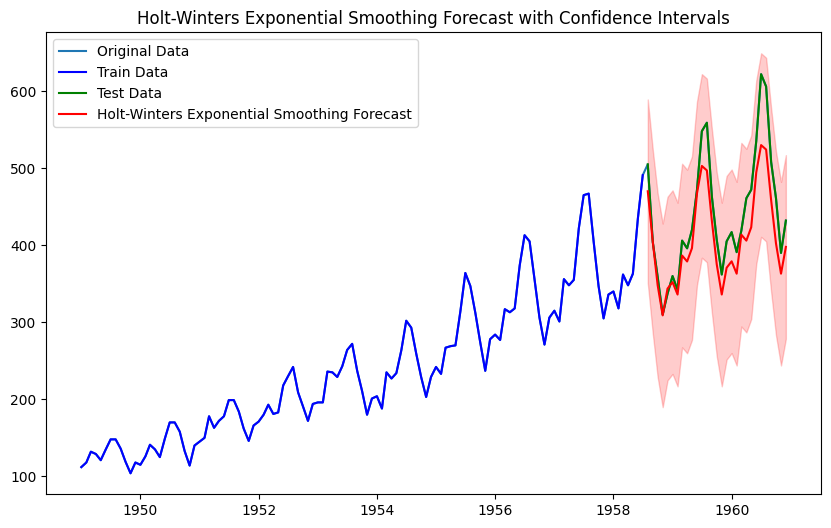

In [26]:
# Holt-Winters Exponential Smoothing
model_hw = ExponentialSmoothing(train['Passengers'], seasonal='add', trend='add', seasonal_periods=12)
model_hw_fit = model_hw.fit()

# Forecast
hw_forecast = model_hw_fit.forecast(steps=len(test))

# Plot the forecast
plot_forecast(hw_forecast, "Holt-Winters Exponential Smoothing")

**7. Theta Model**

The Theta method works by decomposing the series into two components—one that accounts for the overall trend and another that smooths it. It then uses simple forecasts on these components and combines them for the final prediction.

c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\util\_decorators.py:213: EstimationWarning: Model has no free parameters to estimate. Set optimized=False to suppress this warning
  return func(*args, **kwargs)
c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


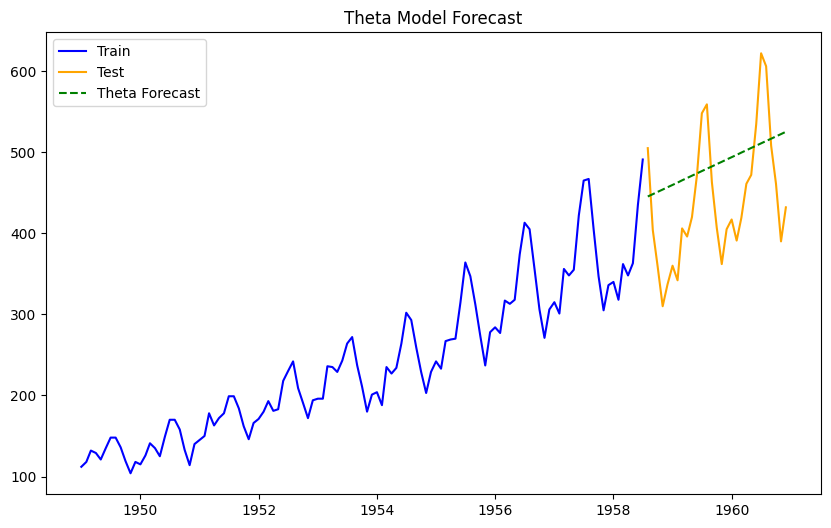

In [27]:
# Theta = 0 (Smoothing Component)
model_theta0 = SimpleExpSmoothing(train['Passengers']).fit(smoothing_level=0.2)
forecast_theta0 = model_theta0.forecast(len(test))

# Theta = 2 (Linear Component)
model_theta2 = Holt(train['Passengers']).fit()
forecast_theta2 = model_theta2.forecast(len(test))

# Combine the forecasts
theta_forecast = 0.5 * (forecast_theta0 + forecast_theta2)

# Plotting the results
plt.figure(figsize=(10, 6))
plt.plot(train.index, train['Passengers'], label='Train', color='blue')
plt.plot(test.index, test['Passengers'], label='Test', color='orange')
plt.plot(test.index, theta_forecast, label='Theta Forecast', color='green', linestyle="--")
plt.legend()
plt.title("Theta Model Forecast")
plt.show()

**8. ARIMA**

**Model parameters:**

- **p**: from ACF (1)
- **q**: from PACF (1)
- **d**: order of integration (2)

In [28]:
ARIMA_model = ARIMA(train["Passengers"], order=(1,2,1))
ARIMA_model_fit = ARIMA_model.fit()

c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [29]:
ARIMA_pred = ARIMA_model_fit.get_prediction(115, 143).predicted_mean

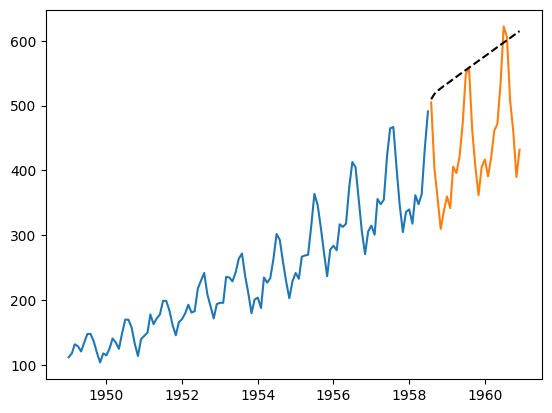

In [30]:
plt.plot(train["Passengers"])
plt.plot(test["Passengers"])
plt.plot(ARIMA_pred, 'k--', label='ARIMA') 
plt.show()

We are not considering seasonality here, let's try with AUTO-ARIMA, that automatically sets the best parameters and considers seasonality.

**9. AUTO-ARIMA**

**Model Parameters**

- Training data
- start_p: At what number should we start searching for the p value for the AR(p) part?
- start_q: At what number should we start searching for the q value for the MA(q) part?
- test=’adf’: use adftest to find optimal ‘d’
- max_p: The maximum value that the p parameter can take.
- max_q: The maximum value that the q parameter can take.
- m:frequency. If it is 1, we say there is no seasonality.
- d: order of integration
- seasonal: is there seasonality or not?

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,1,1)[12]             : AIC=757.714, Time=2.46 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=757.826, Time=0.14 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=755.750, Time=0.50 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=756.380, Time=0.45 sec
 ARIMA(1,1,0)(0,1,0)[12]             : AIC=755.499, Time=0.08 sec
 ARIMA(1,1,0)(0,1,1)[12]             : AIC=755.982, Time=0.44 sec
 ARIMA(1,1,0)(1,1,1)[12]             : AIC=757.649, Time=0.39 sec
 ARIMA(2,1,0)(0,1,0)[12]             : AIC=756.771, Time=0.15 sec
 ARIMA(1,1,1)(0,1,0)[12]             : AIC=756.022, Time=0.17 sec
 ARIMA(0,1,1)(0,1,0)[12]             : AIC=756.011, Time=0.09 sec
 ARIMA(2,1,1)(0,1,0)[12]             : AIC=757.976, Time=0.21 sec
 ARIMA(1,1,0)(0,1,0)[12] intercept   : AIC=757.438, Time=0.16 sec

Best model:  ARIMA(1,1,0)(0,1,0)[12]          
Total fit time: 5.288 seconds


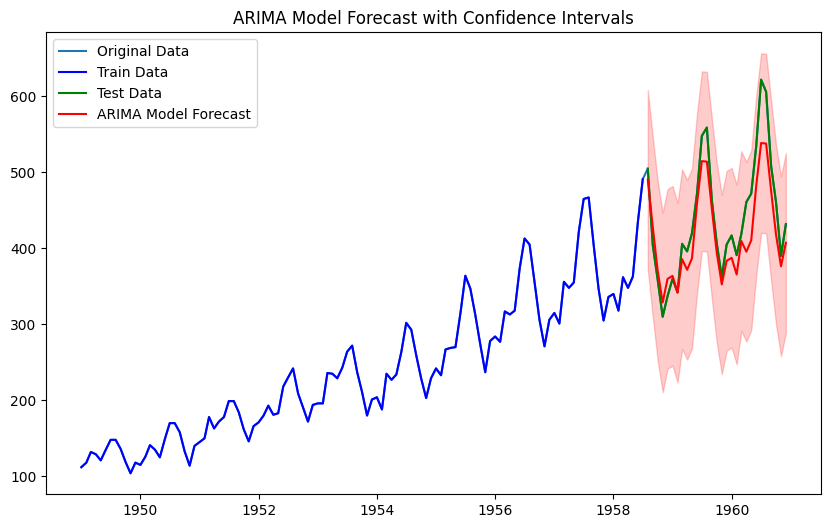

In [31]:
arima_model = auto_arima(train, seasonal=True, m=12, trace=True, error_action="ignore", suppress_warnings=True)
arima_forecast = pd.Series(arima_model.predict(n_periods=len(test)), index=test.index)
plot_forecast(arima_forecast, "ARIMA Model")

**10. SARIMA for Seasonal Data**

Determine SARIMA parameters (p, d, q)(P, D, Q, m) using domain knowledge or automated tools like pmdarima’s auto_arima.

(p,d,q) and (P,D,Q) are the same as ARIMA. m is the seasonality.

c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


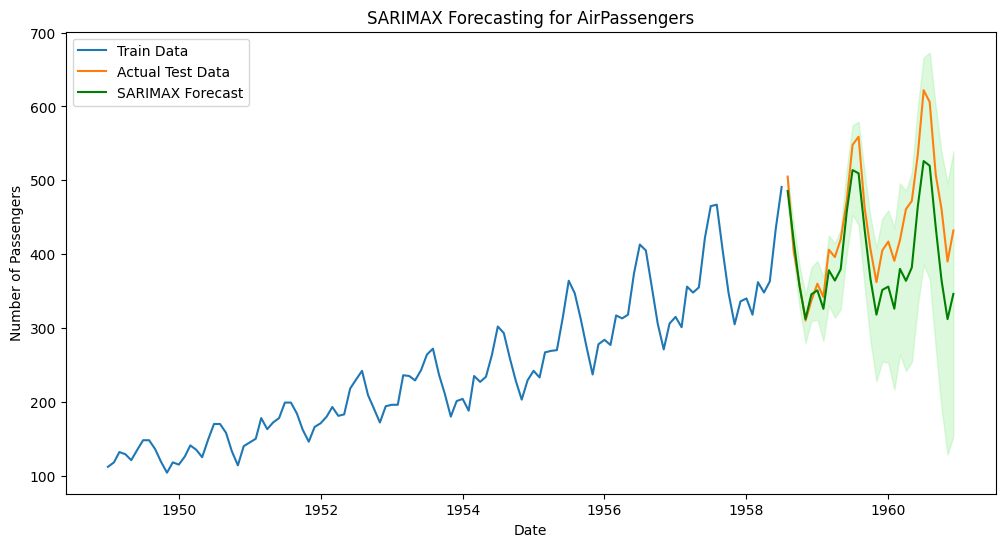

In [32]:
# Fit SARIMAX model (tuned parameters: adjust as needed)
sarimax_model = SARIMAX(train, order=(1, 2, 1), seasonal_order=(1, 2, 1, 12), enforce_stationarity=False, enforce_invertibility=False)
sarimax_result = sarimax_model.fit(disp=False)

# Forecast for the next 29 points
forecast = sarimax_result.get_forecast(steps=29)
forecast_mean_sarimax = forecast.predicted_mean
confidence_intervals = forecast.conf_int()

# Plotting the results
plt.figure(figsize=(12, 6))
plt.plot(train.index, train['Passengers'], label='Train Data')
plt.plot(test.index, test['Passengers'], label='Actual Test Data')
plt.plot(test.index, forecast_mean_sarimax, label='SARIMAX Forecast', color='green')
plt.fill_between(test.index, 
                 confidence_intervals.iloc[:, 0], 
                 confidence_intervals.iloc[:, 1], color='lightgreen', alpha=0.3)
plt.legend()
plt.title("SARIMAX Forecasting for AirPassengers")
plt.xlabel("Date")
plt.ylabel("Number of Passengers")
plt.show()

**10. Regression Models (Random Forest, XGBoost)**

**Random Forest**

In [33]:
# Feature Engineering: Creating lagged features
data['lag1'] = data['Passengers'].shift(1)
data['lag2'] = data['Passengers'].shift(2)
data['lag3'] = data['Passengers'].shift(3)
data.dropna(inplace=True)

Lag Features: We create lag1, lag2, and lag3 as input features to the model. These represent the passenger numbers from the past three months.

In [34]:
# Splitting the data into train and test sets
train_data, test_data = train_test_split(data, test_size=0.2, shuffle=False)

X_train = train_data[['lag1', 'lag2', 'lag3']]
y_train = train_data['Passengers']
X_test = test_data[['lag1', 'lag2', 'lag3']]
y_test = test_data['Passengers']

In [35]:
# Initialize and fit the Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=0)
rf_model.fit(X_train, y_train)

RandomForestRegressor(random_state=0)

In [36]:
# Forecasting on the test set
y_pred_rf = rf_model.predict(X_test)

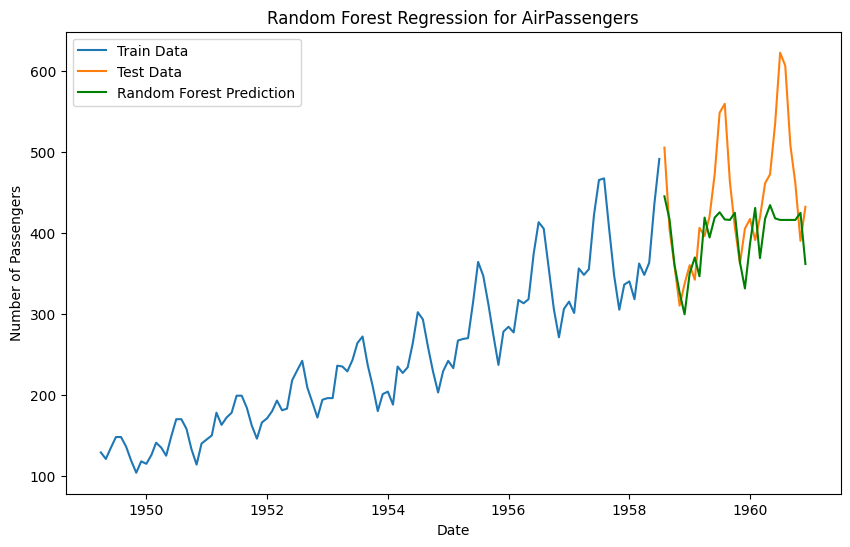

In [37]:
# Plotting the predictions and actual values
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data['Passengers'], label='Train Data')
plt.plot(test_data.index, y_test, label='Test Data')
plt.plot(test_data.index, y_pred_rf, label='Random Forest Prediction', color='green')
plt.legend()
plt.title("Random Forest Regression for AirPassengers")
plt.xlabel("Date")
plt.ylabel("Number of Passengers")
plt.show()

**XGBoost**

In [38]:
# Feature Engineering: Creating lagged features
data['lag1'] = data['Passengers'].shift(1)
data['lag2'] = data['Passengers'].shift(2)
data['lag3'] = data['Passengers'].shift(3)
data.dropna(inplace=True)

In [39]:
# Splitting the data into train and test sets
train_data, test_data = train_test_split(data, test_size=29, shuffle=False)

X_train = train_data[['lag1', 'lag2', 'lag3']]
y_train = train_data['Passengers']
X_test = test_data[['lag1', 'lag2', 'lag3']]
y_test = test_data['Passengers']

In [40]:
# Initialize and fit the XGBoost model
xgb_model = XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=0)
xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=100, n_jobs=None,
             num_parallel_tree=None, random_state=0, ...)

In [41]:
# Forecasting on the test set
y_pred_xgboost = xgb_model.predict(X_test)

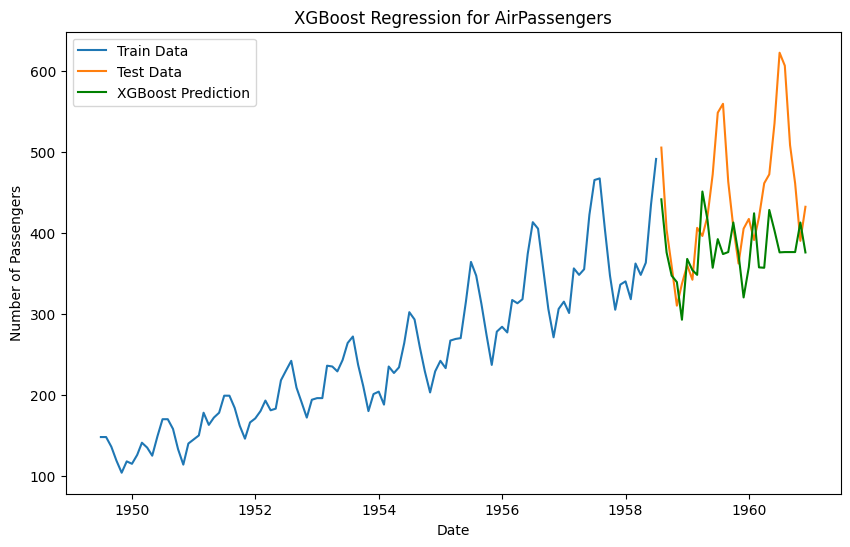

In [42]:
# Plotting the predictions and actual values
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, train_data['Passengers'], label='Train Data')
plt.plot(test_data.index, y_test, label='Test Data')
plt.plot(test_data.index, y_pred_xgboost, label='XGBoost Prediction', color='green')
plt.legend()
plt.title("XGBoost Regression for AirPassengers")
plt.xlabel("Date")
plt.ylabel("Number of Passengers")
plt.show()

# **10. Evaluation**

In [43]:
results = {
    "Model": ["Naïve","Seasonal Naïve","Moving Average","Rolling Moving Average", "STL", "Holt-Winters", "Theta", "ARIMA","AUTO-ARIMA","SARIMA", "Random Forest", "XGBoost"],
    "MSE": [
        mean_squared_error(test, naive_forecast),
        mean_squared_error(test, seasonal_naive_forecast),
        mean_squared_error(test, moving_avg_forecast),
        mean_squared_error(test, rolling_moving_avg_forecast),
        mean_squared_error(test, stl_forecast),
        mean_squared_error(test, hw_forecast),
        mean_squared_error(test, theta_forecast),
        mean_squared_error(test, ARIMA_pred),
        mean_squared_error(test, arima_forecast),
        mean_squared_error(test, forecast_mean_sarimax),
        mean_squared_error(test, y_pred_rf),
        mean_squared_error(test, y_pred_xgboost)
    ],
    "MAE": [
        mean_absolute_error(test, naive_forecast),
        mean_absolute_error(test, seasonal_naive_forecast),
        mean_absolute_error(test, moving_avg_forecast),
        mean_absolute_error(test, rolling_moving_avg_forecast),
        mean_absolute_error(test, stl_forecast),
        mean_absolute_error(test, hw_forecast),
        mean_absolute_error(test, theta_forecast),
        mean_absolute_error(test, ARIMA_pred),
        mean_absolute_error(test, arima_forecast),
        mean_absolute_error(test, forecast_mean_sarimax),
        mean_absolute_error(test, y_pred_rf),
        mean_absolute_error(test, y_pred_xgboost)
    ]
}


In [44]:
results_df = pd.DataFrame(results)
results_df

,Model,MSE,MAE
0,Naïve,8673.931034,81.448276
1,Seasonal Naïve,5660.137931,64.758621
2,Moving Average,10197.547893,76.942529
3,Rolling Moving Average,9238.116988,71.176364
4,STL,5676.729103,64.537972
5,Holt-Winters,1541.395743,31.791027
6,Theta,7022.519019,75.350794
7,ARIMA,20550.816544,126.992583
8,AUTO-ARIMA,1230.803772,28.547409
9,SARIMA,3168.281184,47.336489


# **Cross-Validation**

We will use Scikit-learn's TimeSeriesSplit for cross-validation in time series data rather than manually implementing an expanding window approach. This split method will be compatible with models that require sequential data, ensuring the training data only includes data points before the test set.

Here's an example setup using TimeSeriesSplit for some models in your list, including Naïve, Moving Average, Holt-Winters, ARIMA, Random Forest, and XGBoost.

In [45]:
# Define TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=6)

In [46]:
# Model-specific functions
def naive_forecast(train, horizon):
    return np.repeat(train.iloc[-1], horizon)

def moving_average_forecast(train, window=3):
    return np.mean(train.iloc[-window:])

def holt_winters_forecast(train, horizon):
    model = ExponentialSmoothing(train, seasonal="add", seasonal_periods=12)
    fit = model.fit()
    return fit.forecast(horizon)

def arima_forecast(train, horizon):
    model = ARIMA(train, order=(1, 2, 1))
    fit = model.fit()
    return fit.forecast(horizon)

In [52]:
# Dictionary to store MSE results for each model
results = {model: [] for model in ["Naive", "Moving Average", "Holt-Winters", "ARIMA", "Random Forest", "XGBoost"]}

In [48]:
# Cross-validation loop using TimeSeriesSplit
for train_index, test_index in tscv.split(data):
    train_data = data.iloc[train_index]["Passengers"]
    test_data = data.iloc[test_index]["Passengers"]
    horizon = len(test_data)

    # Naive Model
    naive_pred = naive_forecast(train_data, horizon)
    results["Naive"].append(mean_squared_error(test_data, naive_pred))

    # Moving Average
    moving_avg_pred = moving_average_forecast(train_data, window=3)
    results["Moving Average"].append(mean_squared_error(test_data, [moving_avg_pred] * horizon))

    # Holt-Winters
    hw_pred = holt_winters_forecast(train_data, horizon)
    results["Holt-Winters"].append(mean_squared_error(test_data, hw_pred))

    # ARIMA
    arima_pred = arima_forecast(train_data, horizon)
    results["ARIMA"].append(mean_squared_error(test_data, arima_pred))

    # Random Forest Regressor
    X_train = np.arange(len(train_data)).reshape(-1, 1)
    y_train = train_data.values
    X_test = np.arange(len(train_data), len(train_data) + horizon).reshape(-1, 1)
    rf = RandomForestRegressor()
    rf.fit(X_train, y_train)
    rf_pred = rf.predict(X_test)
    results["Random Forest"].append(mean_squared_error(test_data, rf_pred))

    # XGBoost Regressor
    xgb = XGBRegressor()
    xgb.fit(X_train, y_train)
    xgb_pred = xgb.predict(X_test)
    results["XGBoost"].append(mean_squared_error(test_data, xgb_pred))

c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\carpi\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\carpi\AppData\Local\Programs\Python\Python312\L

In [ ]:
# Calculate the mean MSE across all splits for each model
mean_mse_results = {model: np.mean(errors) for model, errors in results.items()}
print(mean_mse_results)

{'Naive': 3626.5087719298244, 'Moving Average': 4454.474658869395, 'Holt-Winters': 1762.7937345056391, 'ARIMA': 2929.880045386433, 'Random Forest': 3973.4678114035087, 'XGBoost': 3629.9720258062457}


- TimeSeriesSplit: This ensures that each training set includes only the time steps before the corresponding test set, which is essential for time series forecasting.
- Model Predictions: For each fold, we fit the models on the training set and generate predictions for the test set.
- Error Calculation: MSE is computed for each fold’s predictions and averaged across splits for each model.
- Results: The final output shows the mean MSE across all splits for each model, allowing comparison between model performances.

This cross-validation approach using TimeSeriesSplit is effective and ensures consistency in evaluations across different time series models.